 ### 1.Importing Libraries

- **pandas / numpy:** loading, cleaning, and manipulating the data.
- **matplotlib / seaborn:** data visualization.
- **scikit-learn:** splitting the data and building the preprocessing pipeline (`train_test_split`, `ColumnTransformer`, `Pipeline`, `SimpleImputer`, `OneHotEncoder`, `StandardScaler`).

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay

)
from sklearn.model_selection import StratifiedKFold, cross_val_score


## 2. Data Loading and Initial Inspection

In this section, we load the loan approval dataset and inspect its structure, data types, missing values, and duplicate records before preprocessing. 

In [10]:


# Load the dataset
df = pd.read_csv("loan_approval_dataset.csv")

# Clean column names and text values
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Display the first rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Inspect data types and non-null values
df.info()

# Count missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


Dataset shape: (4269, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB

Mis

## 3. Identifying Numerical and Categorical Columns

Here we list all columns and separate them into numerical and categorical types. This helps us decide which preprocessing steps to apply to each group later.

In [11]:
# Display column names
print("Columns:")
print(df.columns.tolist())

# Separate numerical and categorical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\nNumerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Columns:
['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']

Numerical columns:
['loan_id', 'no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

Categorical columns:
['education', 'self_employed', 'loan_status']


## 4. Train-Test Split and Preprocessing Pipeline

We separate the features from the target (`loan_status`), drop the ID column (`loan_id`), and encode the target as `Approved = 1` and `Rejected = 0`.

The preprocessing pipeline works as follows:
- **Numerical features:** missing values are imputed with the median, then scaled using `StandardScaler`.
- **Categorical features:** missing values are imputed with the most frequent value, then encoded using One-Hot Encoding.

Finally, the data is split into 80% training and 20% testing sets, using stratification to preserve the class balance of the target.

In [12]:
# Safety clean (works even if cell 1 was not re-run)
df = df.copy()
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Columns after cleaning:", df.columns.tolist())
print("Target values:", df["loan_status"].unique())

# Separate features and target
target_col = "loan_status"

if target_col not in df.columns:
    raise ValueError(
        f"Target column '{target_col}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Remove rows with missing target labels
df_model = df.dropna(subset=[target_col]).copy()

# Remove ID columns if present
id_cols = [
    col for col in df_model.columns
    if col.lower() in ["loan_id", "id"]
]

X = df_model.drop(columns=[target_col] + id_cols)

# Encode target: Approved = 1, Rejected = 0
y = (df_model[target_col] == "Approved").astype(int)

# Identify feature types
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts())

Columns after cleaning: ['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']
Target values: ['Approved' 'Rejected']
Training features: (3415, 11)
Testing features: (854, 11)
Training target distribution:
loan_status
1    2125
0    1290
Name: count, dtype: int64


### 5.Defining the Models

Each model is wrapped in a `Pipeline` together with the `preprocessor`, so scaling and encoding are learned only from the training data (no data leakage).

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

### 6.Training and Evaluating the Models

Every model is trained on the training set and evaluated on the test set using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

In [15]:
results = []

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df.sort_values("F1-score", ascending=False))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Gradient Boosting,0.9824,0.9831,0.9887,0.9859,0.9976
Random Forest,0.9813,0.9849,0.9849,0.9849,0.9986
Logistic Regression,0.9145,0.9210,0.9435,0.9321,0.9726


### 7.Cross-Validation

5-fold stratified cross-validation gives a more reliable estimate of performance than a single train-test split.

In [19]:


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    cv_results[name] = (scores.mean(), scores.std())

cv_df = pd.DataFrame(cv_results, index=["Mean F1", "Std"]).T.round(4)
display(cv_df)

,Mean F1,Std
Logistic Regression,0.9313,0.0129
Random Forest,0.9824,0.0011
Gradient Boosting,0.9852,0.0032


### 8.Confusion Matrix and ROC Curve

We visualize the performance of all models: the confusion matrices show the types of errors, and the ROC curves compare how well each model separates approved from rejected loans.

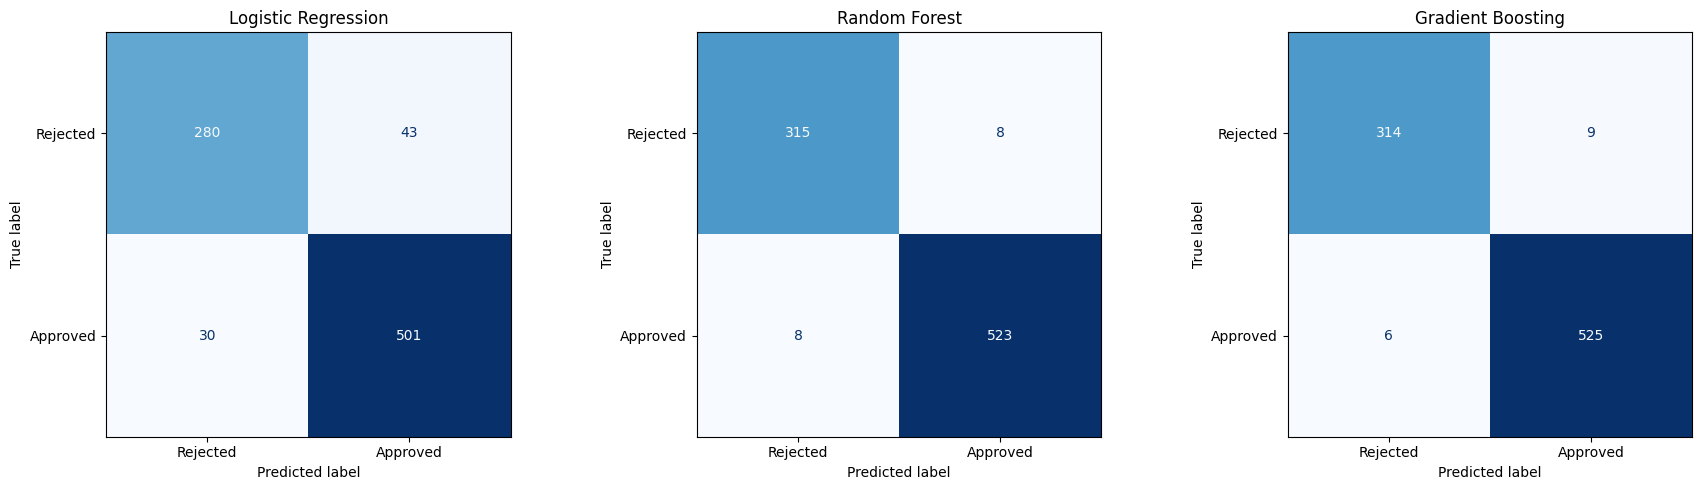

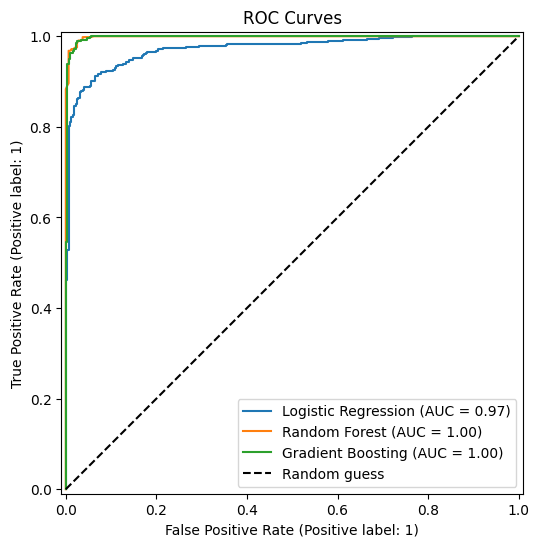

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pipe) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_test, y_test,
        display_labels=["Rejected", "Approved"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC Curves")
plt.legend()
plt.show()

### 9.Feature Importance

Using the Random Forest model, we check which features influence the loan decision the most.

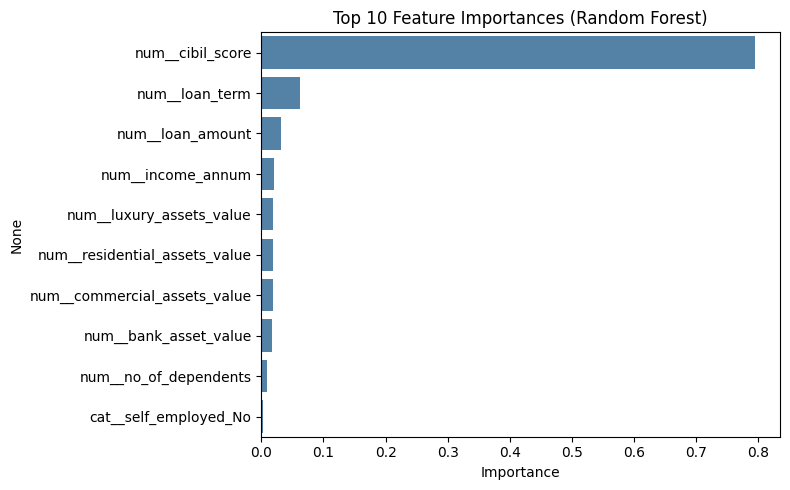

In [20]:
rf_pipe = pipelines["Random Forest"]

feature_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_

fi = (
    pd.Series(importances, index=feature_names)
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=fi.values, y=fi.index, color="steelblue")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### 10.Final Report and Saving the Best Model

We print the detailed classification report for the best model (by F1-score) and save it to disk so it can be reused for predictions.

In [22]:
import joblib

best_name = results_df["F1-score"].idxmax()
best_pipe = pipelines[best_name]

print("Best model:", best_name)
print(classification_report(
    y_test, best_pipe.predict(X_test),
    target_names=["Rejected", "Approved"]
))

joblib.dump(best_pipe, "best_loan_model.joblib")
print("Model saved as best_loan_model.joblib")

Best model: Gradient Boosting
              precision    recall  f1-score   support

    Rejected       0.98      0.97      0.98       323
    Approved       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854

Model saved as best_loan_model.joblib


### 11.Predicting a New Loan Application

Example of using the saved model to predict the status of a new application.

In [23]:
loaded_model = joblib.load("best_loan_model.joblib")

new_applicant = pd.DataFrame([{
    "no_of_dependents": 2,
    "education": "Graduate",
    "self_employed": "No",
    "income_annum": 9000000,
    "loan_amount": 25000000,
    "loan_term": 12,
    "cibil_score": 750,
    "residential_assets_value": 5000000,
    "commercial_assets_value": 8000000,
    "luxury_assets_value": 20000000,
    "bank_asset_value": 7000000,
}])

pred = loaded_model.predict(new_applicant)[0]
proba = loaded_model.predict_proba(new_applicant)[0, 1]

print("Prediction:", "Approved" if pred == 1 else "Rejected")
print(f"Approval probability: {proba:.2%}")

Prediction: Approved
Approval probability: 99.85%
